# Chapitre 1. Espace probabilisé et dénombrement

Compter avec `math.comb` et `math.perm`, et vérifier par simulation.

*Cours « Probabilités pour la gestion des risques », M1 GRAF. Exécutez les cellules dans l'ordre (Maj + Entrée).*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, integrate
from math import comb, perm, factorial, log, exp

rng = np.random.default_rng(42)   # graine : memes resultats a chaque execution

## Les outils de dénombrement

In [2]:
print('PIN 4 chiffres     :', 10**4)
print('Podium 3 parmi 10  :', perm(10, 3))
print('Comite 3 parmi 10  :', comb(10, 3))
print('5 candidats ranges :', factorial(5))

PIN 4 chiffres     : 10000
Podium 3 parmi 10  : 720
Comite 3 parmi 10  : 120
5 candidats ranges : 120


## Exemple résolu : Audit de dossiers
20 dossiers dont 4 frauduleux, on en tire 3. P(au moins une fraude) ?

In [3]:
exact = 1 - comb(16, 3) / comb(20, 3)
print('Exact :', exact)

dossiers = np.array([1]*4 + [0]*16)
n_sim = 200_000
trouve = sum(rng.choice(dossiers, size=3, replace=False).sum() >= 1 for _ in range(n_sim))
print('Simulation :', trouve / n_sim)

Exact : 0.5087719298245614


Simulation : 0.51074


## [N3] Paradoxe des anniversaires

10 0.1169
20 0.4114
23 0.5073
30 0.7063
50 0.9704


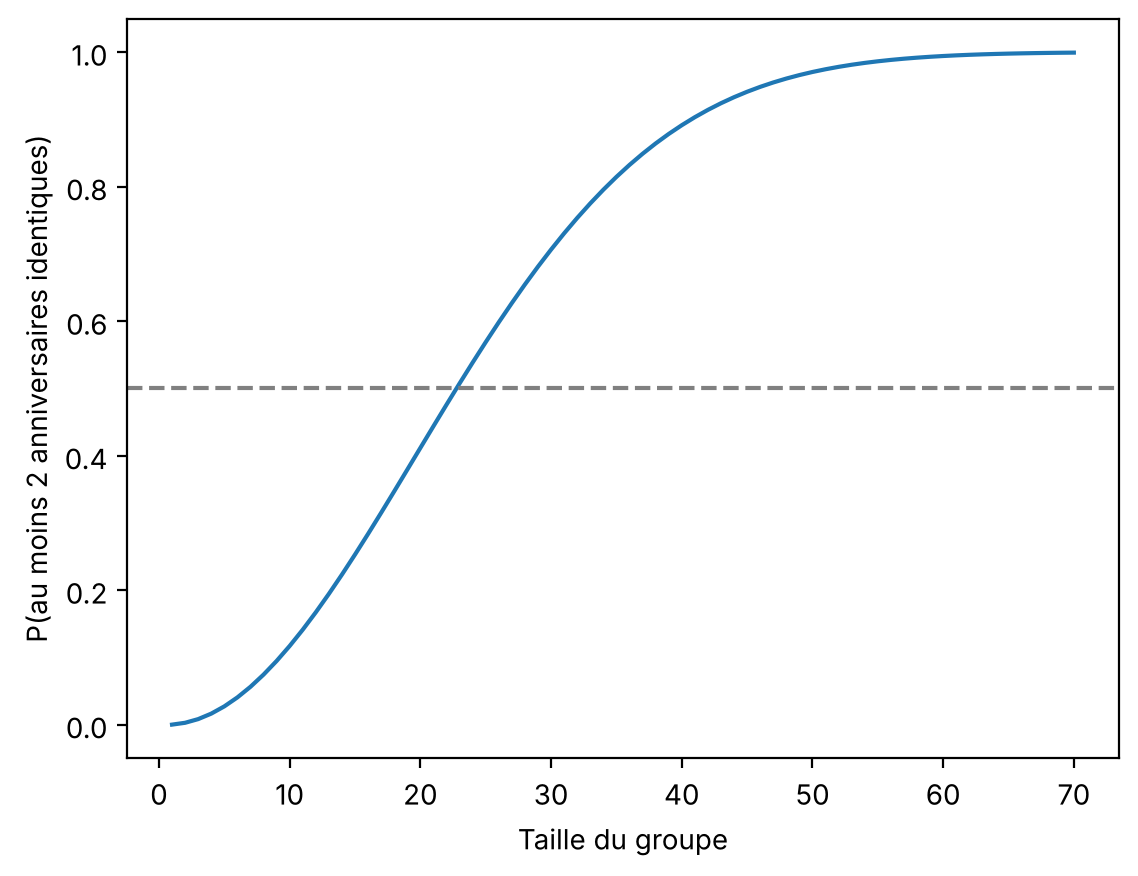

In [4]:
def p_anniv(n):
    return 1 - perm(365, n) / 365**n

for n in [10, 20, 23, 30, 50]:
    print(n, round(p_anniv(n), 4))

ns = np.arange(1, 71)
plt.plot(ns, [p_anniv(int(n)) for n in ns]); plt.axhline(0.5, ls='--', color='grey')
plt.xlabel('Taille du groupe'); plt.ylabel('P(au moins 2 anniversaires identiques)'); plt.show()

## Vérification des exercices 1.1 à 1.5

In [5]:
print('1.1 :', round(0.4 + 0.3 - 0.5, 4), round(0.4 - (0.4 + 0.3 - 0.5), 4))
print('1.2 :', perm(10, 4) / 10**4)
print('1.3 :', comb(5, 1) * comb(45, 3) / comb(50, 4))
print('1.4 :', 1 / comb(49, 6), '(1 sur', comb(49, 6), ')')
pA, pH, pAH = 0.10, 0.05, 0.02
print('1.5 : (a)', round(pA + pH - pAH, 4), '(b)', round(1 - (pA + pH - pAH), 4),
      '(c)', round(pA + pH - 2*pAH, 4), '(d)', round(pA - pAH, 4))

# 1.3 par simulation
contrats = np.array([1]*5 + [0]*45)
res = [rng.choice(contrats, size=4, replace=False).sum() == 1 for _ in range(100_000)]
print('1.3 simulation :', np.mean(res))

1.1 : 0.2 0.2
1.2 : 0.504
1.3 : 0.308076422058185
1.4 : 7.151123842018516e-08 (1 sur 13983816 )
1.5 : (a) 0.13 (b) 0.87 (c) 0.11 (d) 0.08


1.3 simulation : 0.30926
